# ProteinGym Benchmark: Comprehensive Evaluation

This notebook presents a broad evaluation of SMITEpro across the entire ProteinGym single-mutant benchmark dataset. We benchmark against EVOLVEpro using a standardized training protocol to ensure fair comparison:

1. **Training Set**: For each protein, we selected 64 mutations ensuring unique site coverage (one mutation per position max) to test generalization to unseen sites.
2. **Models**:
   - **Zero-Shot ESMC**: Baseline without fine-tuning.
   - **EVOLVEpro**: Comparison SOTA method.
   - **SMITEpro**: Our margin-ranking fine-tuner.
   - **Combined**: An ensemble averaging the normalized predictions of SMITEpro and EVOLVEpro.

We analyze performance (Spearman's $\rho$) across different protein categories (eukaryotic, prokaryotic, viral) and sequence lengths to identify where our method excels. Initial findings suggest SMITEpro adapts better to larger, complex proteins, while EVOLVEpro holds an edge on smaller targets where the training data covers a larger fraction of the sequence.

In [82]:
import pandas as pd
import os
import numpy as np

dir_path = '.'
system = []
lengths = []
plengths = []
num_sites = []

my_rho_values = []
epro_rho_values = []
zero_shot_rho_values = []
combined_rho_values = []
SMITEpro_ndcg_values = []
EVOLVEpro_ndcg_values = []

# Set your screening budget here
n = 10 
        
for file in os.listdir(dir_path):
    if not file.endswith('predictions_shot64.csv'):
        continue
        
    df = pd.read_csv(os.path.join(dir_path, file))
    
    df['pred_my_method_norm'] = (df['pred_my_method'] - df['pred_my_method'].min()) / (df['pred_my_method'].max() - df['pred_my_method'].min())
    df['pred_epro_norm'] = (df['pred_epro'] - df['pred_epro'].min()) / (df['pred_epro'].max() - df['pred_epro'].min())
    df['pred_combined'] = (df['pred_my_method_norm'] + df['pred_epro_norm']) / 2

    my_rho = df[['pred_my_method', 'target']].corr(method='spearman').iloc[0,1]
    epro_rho = df[['pred_epro', 'target']].corr(method='spearman').iloc[0,1]
    zero_shot_rho = df[['delta_esm', 'target']].corr(method='spearman').iloc[0,1]
    combined_rho = df[['pred_combined', 'target']].corr(method='spearman').iloc[0,1]
    
    my_rho_values.append(my_rho)
    epro_rho_values.append(epro_rho)
    zero_shot_rho_values.append(zero_shot_rho)
    combined_rho_values.append(combined_rho)

    system.append(file.replace('.csv', '').split('_')[1])
    lengths.append(len(df))
    plengths.append(len(df['mutated_sequence'][0]))
    
    unique_sites = set()
    for pos in df['mutant']:
        positions = pos.split(':')
        for position in positions:
            unique_sites.add(position[1:-1])
    num_sites.append(len(unique_sites))

    # --- Custom NDCG Calculation ---
    min_target = df['target'].min()
    ideal_top_n = df.nlargest(n, 'target')['target'].values
    ideal_shifted_rels = ideal_top_n - min_target
    idcg = np.sum(ideal_shifted_rels / np.log2(np.arange(2, n + 2)))

    # EVOLVEpro NDCG
    pred_top_n_epro = df.nlargest(n, 'pred_epro')
    relevances_epro = pred_top_n_epro['target'].values
    shifted_rels_epro = relevances_epro - min_target
    dcg_epro = np.sum(shifted_rels_epro / np.log2(np.arange(2, n + 2)))
    epro_ndcg = dcg_epro / idcg if idcg > 0 else 0

    # my NDCG
    pred_top_n_my = df.nlargest(n, 'pred_my_method')
    relevances_my = pred_top_n_my['target'].values
    shifted_rels_my = relevances_my - min_target
    dcg_my = np.sum(shifted_rels_my / np.log2(np.arange(2, n + 2)))
    my_ndcg = dcg_my / idcg if idcg > 0 else 0
    
    SMITEpro_ndcg_values.append(my_ndcg)
    EVOLVEpro_ndcg_values.append(epro_ndcg)

my_rho_values = [x for x in my_rho_values if pd.notna(x)]
epro_rho_values = [x for x in epro_rho_values if pd.notna(x)]
zero_shot_rho_values = [x for x in zero_shot_rho_values if pd.notna(x)]
combined_rho_values = [x for x in combined_rho_values if pd.notna(x)]

avg_SMITEpro_ndcg = sum(SMITEpro_ndcg_values) / len(SMITEpro_ndcg_values) if SMITEpro_ndcg_values else 0
avg_EVOLVEpro_ndcg = sum(EVOLVEpro_ndcg_values) / len(EVOLVEpro_ndcg_values) if EVOLVEpro_ndcg_values else 0

print(f"Average SMITEpro NDCG@{n}: {avg_SMITEpro_ndcg:.4f}")
print(f"Average EVOLVEpro NDCG@{n}: {avg_EVOLVEpro_ndcg:.4f}")

Average SMITEpro NDCG@10: 0.6891
Average EVOLVEpro NDCG@10: 0.7716


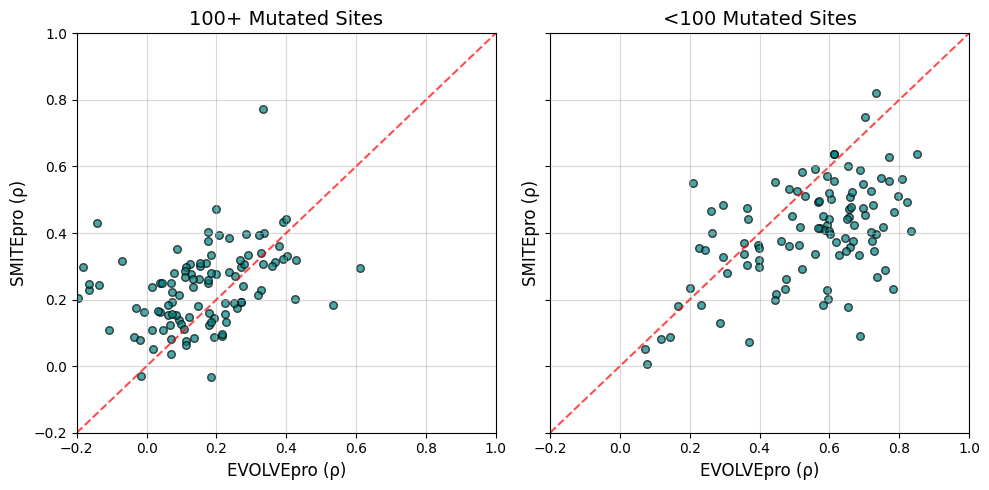

In [83]:
import matplotlib.pyplot as plt

# Split data based on number of mutated sites
epro_large, combined_large = [], []
epro_small, combined_small = [], []

for n, mr, er in zip(num_sites, my_rho_values, epro_rho_values):
    if n >= 100:
        epro_large.append(er)
        combined_large.append(mr)
    else:
        epro_small.append(er)
        combined_small.append(mr)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

subplots_data = [
    (axes[0], "100+ Mutated Sites", epro_large, combined_large),
    (axes[1], "<100 Mutated Sites", epro_small, combined_small)
]

for ax, title, xvals, yvals in subplots_data:
    ax.scatter(
        xvals,
        yvals,
        s=30,
        alpha=0.7,
        edgecolors='black',
        c='teal'
    )
    
    # Line of equality
    ax.plot([-0.2, 1.0], [-0.2, 1.0], color="red", linestyle="--", alpha=0.7)
    
    # Formatting
    ax.set_xlim(-0.2, 1.0)
    ax.set_ylim(-0.2, 1.0)
    ax.set_xlabel("EVOLVEpro (ρ)", fontsize=12)
    ax.set_ylabel("SMITEpro (ρ)", fontsize=12)
    ax.set_title(title, fontsize=14)
    ax.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Head-to-Head Comparisons
We directly compare the per-protein performance:
1. **Combined vs. EVOLVEpro**: Does averaging improve upon the SOTA?
2. **SMITEpro vs. EVOLVEpro**: Where do we win/lose?

Points above the diagonal indicate our method (or ensemble) is superior for that target. The color coding distinguishes eukaryotes, prokaryotes, and viruses.

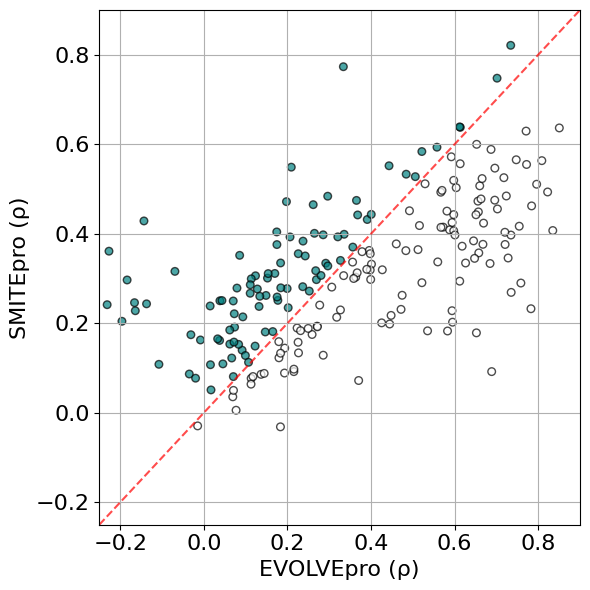

Points above y=x line: 62
Points below y=x line: 3
Points on y=x line: 145
Fraction above y=x line: 0.9538461538461539


In [91]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Determine fill color: teal if SMITEpro is better/equal, white if EVOLVEpro is better
color_list = ['teal' if mr >= er else 'white' for mr, er in zip(my_rho_values, epro_rho_values)]

plt.figure(figsize=(6, 6))
plt.scatter(
    epro_rho_values,
    my_rho_values,
    s=30,
    alpha=0.7,
    edgecolors='black',
    c=color_list
)

plt.xlabel("EVOLVEpro (ρ)", fontsize=16)
plt.ylabel("SMITEpro (ρ)", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.plot([-0.25, 1], [-0.25, 1], color="red", linestyle="--", alpha=0.7)
plt.xlim(-0.25, 0.9)
plt.ylim(-0.25, 0.9)

plt.grid()
plt.tight_layout()

# Calculate the best fit line
slope, intercept, r_value, p_value, std_err = stats.linregress(epro_rho_values, my_rho_values)

plt.show()

# Count how many points are above the y=x line
above = 0
below = 0
tie = 0
for i in range(len(epro_rho_values)):
    if combined_rho_values[i] > epro_rho_values[i] + 0.1:
        above += 1
    elif combined_rho_values[i] < epro_rho_values[i] - 0.1:
        below += 1
    else:
        tie += 1
        
print("Points above y=x line: " + str(above))
print("Points below y=x line: " + str(below))
print("Points on y=x line: " + str(tie))
print("Fraction above y=x line: " + str(above / (above + below)))

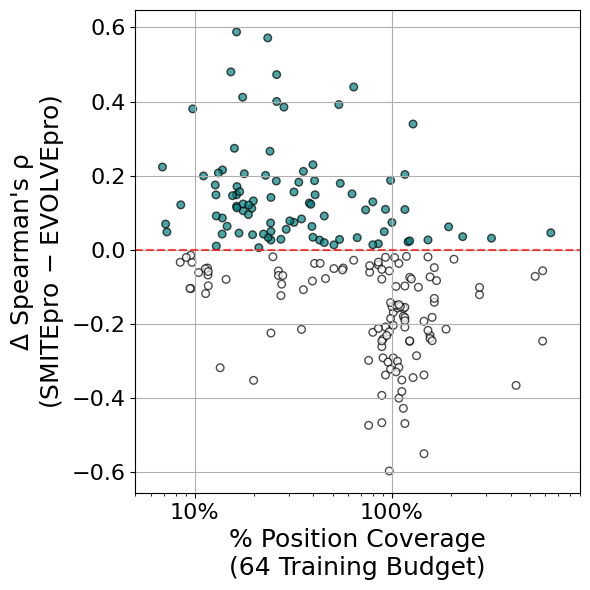

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

# make list
plengths_list = list(plengths)

# plot protein length versus rho difference (combined - epro)
rho_differences = [c - e for c, e in zip(my_rho_values, epro_rho_values)]

# remove points where number of mutated sites is < 10
filtered_data = [(n, p, r) for n, p, r in zip(num_sites, plengths_list, rho_differences) if n >= 10]

filtered_numsites, filtered_plengths, filtered_rho_differences = zip(*filtered_data)

# DMS coverage percentage (64 / total mutated sites)
coverage_percentages = [64 / n for n in filtered_numsites]

# Determine fill color: teal if SMITEpro is better/equal (diff >= 0), white if not
color_list = ['teal' if diff >= 0 else 'white' for diff in filtered_rho_differences]

# plot 1
plt.figure(figsize=(6, 6))

plt.scatter(
    coverage_percentages,
    filtered_rho_differences,
    s=30,
    alpha=0.7,
    edgecolors='black',
    c=color_list
)       

plt.xlabel("% Position Coverage\n(64 Training Budget)", fontsize=18)
plt.ylabel("Δ Spearman's ρ\n(SMITEpro $-$ EVOLVEpro)", fontsize=18)
plt.axhline(0, color='red', linestyle='--', alpha=0.7)

# grey block for coverage > 0.7
# plt.axvspan(0.7, 9.0, alpha=0.2, color='grey')
# set x max to 9
plt.xlim(0.05, 9)

plt.grid()
plt.xscale('log')

# Format the x-axis ticks as percentages using xmax=1.0
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))

# tick text size
plt.tick_params(axis='both', which='major', labelsize=16)

# best fit line
z = np.polyfit(np.log10(coverage_percentages), filtered_rho_differences, 1)
p = np.poly1d(z)
x_vals = np.linspace(min(coverage_percentages), max(coverage_percentages), 100)
# plt.plot(x_vals, p(np.log10(x_vals)), color='blue', linestyle='--', alpha=0.7)

plt.tight_layout()
# plt.savefig("plots/Coverage_vs_RhoDifference.svg", format='svg', dpi=600)
plt.show()

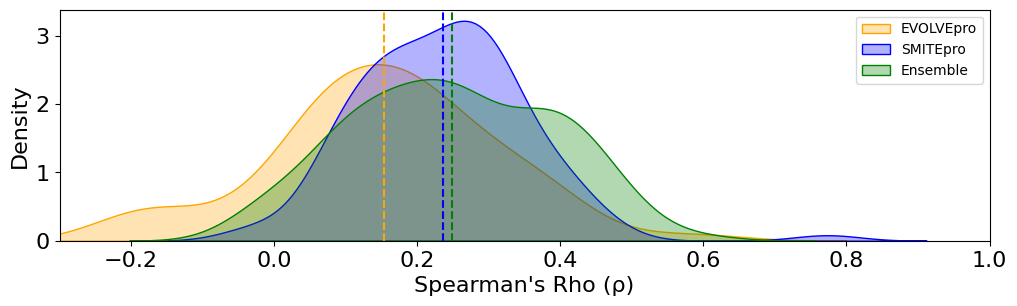

mean of SMITEpro rho values: 0.3170721776056594
mean of Combined rho values: 0.4107454526978393


In [86]:
# Plot distribution of my_rho_values and epro_rho_values

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# filter out values where site coverage is >= 100
filtered_my_rho_values = []
filtered_epro_rho_values = []
filtered_combined_rho_values = []

for n, mr, er in zip(num_sites, my_rho_values, epro_rho_values):
        if 64/n < 0.7:# 1.0:  # coverage percentage <= 100%
            filtered_my_rho_values.append(mr)
            filtered_epro_rho_values.append(er)
            filtered_combined_rho_values.append(combined_rho_values[num_sites.index(n)])


# smooth density
plt.figure(figsize=(12, 3))
# sns.kdeplot(my_rho_values, label='SMITEpro', color='blue', fill=True, alpha=0.3)
sns.kdeplot(filtered_epro_rho_values, label='EVOLVEpro', color='orange', fill=True, alpha=0.3)
sns.kdeplot(filtered_my_rho_values, label='SMITEpro', color='blue', fill=True, alpha=0.3)
sns.kdeplot(filtered_combined_rho_values, label='Ensemble', color='green', fill=True, alpha=0.3)

# set vertical line at means
plt.axvline(x=sum(filtered_my_rho_values) / len(filtered_my_rho_values), color='blue', linestyle='--', label='SMITEpro Mean')
plt.axvline(x=sum(filtered_epro_rho_values) / len(filtered_epro_rho_values), color='orange', linestyle='--', label='EVOLVEpro Mean')
plt.axvline(x=sum(filtered_combined_rho_values) / len(filtered_combined_rho_values), color='green', linestyle='--', label='Ensemble Mean')

plt.legend()
# remove the dashed lines from the legend
handles, labels = plt.gca().get_legend_handles_labels()
handles = [h for h in handles if not isinstance(h, Line2D) or h.get_linestyle() != '--']
labels = [l for h, l in zip(handles, labels) if not isinstance(h, Line2D) or h.get_linestyle() != '--']
plt.legend(handles, labels)
# make tick label size larger
plt.tick_params(axis='both', which='major', labelsize=16)
# make x and y labels larger
plt.xlabel('Spearman\'s Rho (ρ)', fontsize=16)
plt.ylabel('Density', fontsize=16)
# set lims
plt.xlim(-0.3, 1.0)
plt.show()

print("mean of SMITEpro rho values:", sum(my_rho_values) / len(my_rho_values))
# print("mean of EVOLVEpro rho values:", sum(epro_rho_values) / len(epro_rho_values))
print("mean of Combined rho values:", sum(combined_rho_values) / len(combined_rho_values))

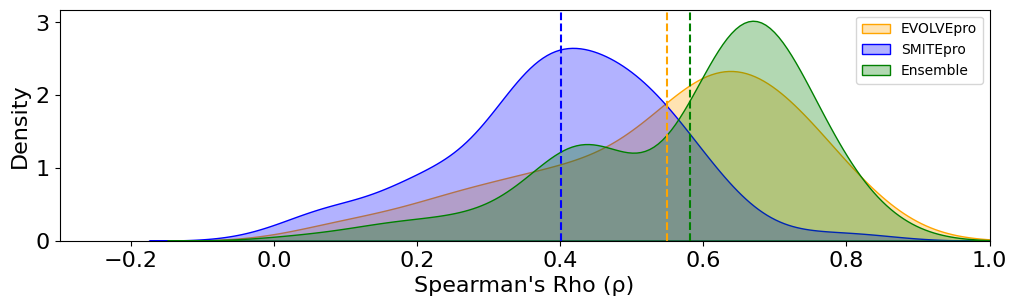

mean of SMITEpro rho values: 0.3170721776056594
mean of Combined rho values: 0.4107454526978393


In [87]:
# Plot distribution of my_rho_values and epro_rho_values

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# filter out values where site coverage is >= 100
filtered_my_rho_values = []
filtered_epro_rho_values = []
filtered_combined_rho_values = []

for n, mr, er in zip(num_sites, my_rho_values, epro_rho_values):
        if 64/n > 0.7:# 1.0:  # coverage percentage <= 100%
            filtered_my_rho_values.append(mr)
            filtered_epro_rho_values.append(er)
            filtered_combined_rho_values.append(combined_rho_values[num_sites.index(n)])


# smooth density
plt.figure(figsize=(12, 3))
# sns.kdeplot(my_rho_values, label='SMITEpro', color='blue', fill=True, alpha=0.3)
sns.kdeplot(filtered_epro_rho_values, label='EVOLVEpro', color='orange', fill=True, alpha=0.3)
sns.kdeplot(filtered_my_rho_values, label='SMITEpro', color='blue', fill=True, alpha=0.3)
sns.kdeplot(filtered_combined_rho_values, label='Ensemble', color='green', fill=True, alpha=0.3)

# set vertical line at means
plt.axvline(x=sum(filtered_my_rho_values) / len(filtered_my_rho_values), color='blue', linestyle='--', label='SMITEpro Mean')
plt.axvline(x=sum(filtered_epro_rho_values) / len(filtered_epro_rho_values), color='orange', linestyle='--', label='EVOLVEpro Mean')
plt.axvline(x=sum(filtered_combined_rho_values) / len(filtered_combined_rho_values), color='green', linestyle='--', label='Ensemble Mean')

plt.legend()
# remove the dashed lines from the legend
handles, labels = plt.gca().get_legend_handles_labels()
handles = [h for h in handles if not isinstance(h, Line2D) or h.get_linestyle() != '--']
labels = [l for h, l in zip(handles, labels) if not isinstance(h, Line2D) or h.get_linestyle() != '--']
plt.legend(handles, labels)
# make tick label size larger
plt.tick_params(axis='both', which='major', labelsize=16)
# make x and y labels larger
plt.xlabel('Spearman\'s Rho (ρ)', fontsize=16)
plt.ylabel('Density', fontsize=16)
# set lims
plt.xlim(-0.3, 1.0)
plt.show()

print("mean of SMITEpro rho values:", sum(my_rho_values) / len(my_rho_values))
# print("mean of EVOLVEpro rho values:", sum(epro_rho_values) / len(epro_rho_values))
print("mean of Combined rho values:", sum(combined_rho_values) / len(combined_rho_values))

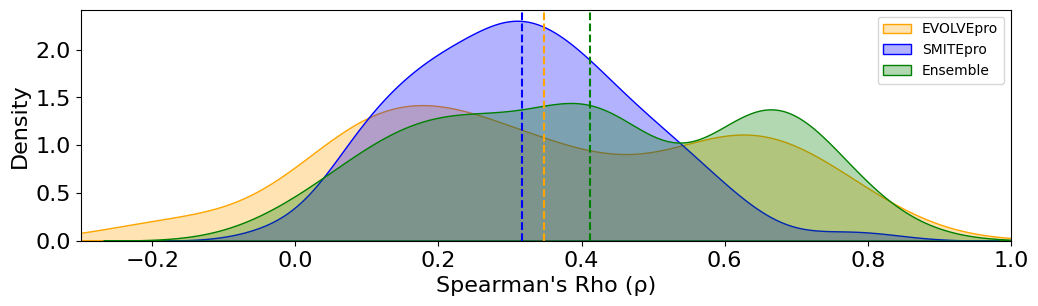

mean of SMITEpro rho values: 0.3170721776056594
mean of Combined rho values: 0.4107454526978393


In [92]:
# Plot distribution of my_rho_values and epro_rho_values

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# filter out values where site coverage is >= 100
filtered_my_rho_values = []
filtered_epro_rho_values = []
filtered_combined_rho_values = []

for n, mr, er in zip(num_sites, my_rho_values, epro_rho_values):
        # if 64/n > 0.7:# 1.0:  # coverage percentage <= 100%
            filtered_my_rho_values.append(mr)
            filtered_epro_rho_values.append(er)
            filtered_combined_rho_values.append(combined_rho_values[num_sites.index(n)])


# smooth density
plt.figure(figsize=(12, 3))
# sns.kdeplot(my_rho_values, label='SMITEpro', color='blue', fill=True, alpha=0.3)
sns.kdeplot(filtered_epro_rho_values, label='EVOLVEpro', color='orange', fill=True, alpha=0.3)
sns.kdeplot(filtered_my_rho_values, label='SMITEpro', color='blue', fill=True, alpha=0.3)
sns.kdeplot(filtered_combined_rho_values, label='Ensemble', color='green', fill=True, alpha=0.3)

# set vertical line at means
plt.axvline(x=sum(filtered_my_rho_values) / len(filtered_my_rho_values), color='blue', linestyle='--', label='SMITEpro Mean')
plt.axvline(x=sum(filtered_epro_rho_values) / len(filtered_epro_rho_values), color='orange', linestyle='--', label='EVOLVEpro Mean')
plt.axvline(x=sum(filtered_combined_rho_values) / len(filtered_combined_rho_values), color='green', linestyle='--', label='Ensemble Mean')

plt.legend()
# remove the dashed lines from the legend
handles, labels = plt.gca().get_legend_handles_labels()
handles = [h for h in handles if not isinstance(h, Line2D) or h.get_linestyle() != '--']
labels = [l for h, l in zip(handles, labels) if not isinstance(h, Line2D) or h.get_linestyle() != '--']
plt.legend(handles, labels)
# make tick label size larger
plt.tick_params(axis='both', which='major', labelsize=16)
# make x and y labels larger
plt.xlabel('Spearman\'s Rho (ρ)', fontsize=16)
plt.ylabel('Density', fontsize=16)
# set lims
plt.xlim(-0.3, 1.0)
plt.show()

print("mean of SMITEpro rho values:", sum(my_rho_values) / len(my_rho_values))
# print("mean of EVOLVEpro rho values:", sum(epro_rho_values) / len(epro_rho_values))
print("mean of Combined rho values:", sum(combined_rho_values) / len(combined_rho_values))